#**Description**

This project aims to develop a deep learning model to detect and classify brain tumors from MRI scan images using Convolutional Neural Networks (CNN). Manual analysis of MRI images can be difficult and time-consuming, so the model helps in faster and more accurate tumor detection.


This project builds a **Deep Learning based Brain Tumor Detection System** using:

* CNN (Convolutional Neural Network)
* Transfer Learning
* MobileNetV2 pretrained model
* MRI scan images

The model learns patterns from MRI images and predicts the tumor category.

# **Goals**
Develop a CNN-based deep learning model for brain tumor classification.
Improve detection accuracy using image preprocessing and augmentation.
Reduce manual effort in identifying tumors from MRI scans.
Evaluate the model using multiple performance metrics.
Expected Outcomes
Accurate classification of brain MRI images.
High model performance in terms of accuracy and F1-score.
Visual comparison of predicted and actual classes.
A deployable deep learning model for medical image classification tasks.


# **Workflow**:
1. Load dataset from Google Drive
2. Extract dataset
3. Explore dataset (EDA)
4. Preprocess and augment images
5. Build MobileNetV2 CNN model
6. Train model
7. Fine tune pretrained layers
8. Evaluate model performance
9. Predict tumor from new MRI image


**Dataset Loaded From Google Drive**

---



In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


**Import Required Libraries**

In [ ]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import random

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

**Define ZIP File Path From Google Drive**

In [ ]:
zip_path = "/content/drive/MyDrive/Capstone Project/brain_tumor_dataset.zip"

**Extract ZIP File**

In [ ]:
extract_path = "/content/extracted_brain_tumor_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


**Check Dataset Structure**

In [ ]:
# Define train and test paths (moved from a later cell for correct execution order)
base_data_path = os.path.join(extract_path, "multi_class_dataset")
train_path = base_data_path
test_path = base_data_path

print("\nTRAINING CLASSES:")
print(os.listdir(train_path))

print("\nTESTING CLASSES:")
print(os.listdir(test_path))


TRAINING CLASSES:
['meningioma', 'pituitary', 'glioma', 'healthy']

TESTING CLASSES:
['meningioma', 'pituitary', 'glioma', 'healthy']


**Define Dataset Paths**

In [ ]:
train_path = base_data_path
test_path = base_data_path

print("Training Path:", train_path)
print("Testing Path:", test_path)

print("Train Exists:", os.path.exists(train_path))
print("Test Exists:", os.path.exists(test_path))

Training Path: /content/extracted_brain_tumor_dataset/multi_class_dataset
Testing Path: /content/extracted_brain_tumor_dataset/multi_class_dataset
Train Exists: True
Test Exists: True


**Check number of data in classes (Before Balancing)**

In [ ]:
class_counts = {}

for cls in os.listdir(train_path):
    path = os.path.join(train_path, cls)
    if os.path.isdir(path):
        class_counts[cls] = len(os.listdir(path))

print("\nCLASS DISTRIBUTION BEFORE BALANCING:")
for k, v in class_counts.items():
    print(k, ":", v)


CLASS DISTRIBUTION BEFORE BALANCING:
meningioma : 3266
pituitary : 2974
glioma : 3325
healthy : 6704


**VISUALIZE**

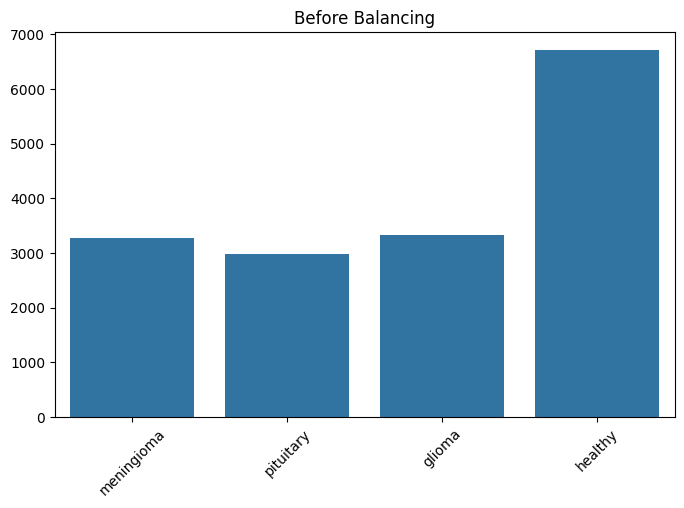

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
plt.title("Before Balancing")
plt.xticks(rotation=45)
plt.show()

**Fix Imbalance**


In [ ]:
counts = list(class_counts.values())

# Auto target (median-based)
target_size = int(sorted(counts)[len(counts)//2])

print("\nAUTO TARGET SIZE:", target_size)

for cls, count in class_counts.items():

    class_path = os.path.join(train_path, cls)

    if count > target_size:

        images = os.listdir(class_path)
        random.shuffle(images)

        remove_count = count - target_size

        print(f"Reducing {cls}: removing {remove_count}")

        for img in images[:remove_count]:
            img_path = os.path.join(class_path, img)
            if os.path.exists(img_path):
                os.remove(img_path)

print("\nDataset Balanced Automatically")


AUTO TARGET SIZE: 3325
Reducing healthy: removing 3379

Dataset Balanced Automatically


**Check number of data in classes (After Balancing)**

In [ ]:
balanced_counts = {}

for cls in os.listdir(train_path):
    path = os.path.join(train_path, cls)
    if os.path.isdir(path):
        balanced_counts[cls] = len(os.listdir(path))

print("\nCLASS DISTRIBUTION AFTER BALANCING:")
for k, v in balanced_counts.items():
    print(k, ":", v)


CLASS DISTRIBUTION AFTER BALANCING:
meningioma : 3266
pituitary : 2974
glioma : 3325
healthy : 3325


**Exploratory Data Analysis**

In [ ]:
# CREATE DATAFRAME OF IMAGE INFORMATION

import pandas as pd

train_path = base_data_path

data = []

classes = os.listdir(train_path)

for label in classes:

    folder_path = os.path.join(train_path, label)

    # Skip if not a folder
    if not os.path.isdir(folder_path):
        continue

    for img_name in os.listdir(folder_path):

        img_path = os.path.join(folder_path, img_name)

        img = cv2.imread(img_path)

        if img is None:
            continue

        height, width, channels = img.shape
        mean_pixel = img.mean()

        data.append([
            label,
            width,
            height,
            mean_pixel
        ])

df = pd.DataFrame(
    data,
    columns=[
        'Class',
        'Width',
        'Height',
        'Mean_Pixel'
    ]
)

df.head()

,Class,Width,Height,Mean_Pixel
0,meningioma,512,512,51.410709
1,meningioma,512,512,45.447712
2,meningioma,512,512,45.622105
3,meningioma,512,512,41.746693
4,meningioma,512,512,57.658485


In [ ]:
# DISPLAY DATASET INFORMATION

print(df.info())

print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12890 entries, 0 to 12889
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Class       12890 non-null  object 
 1   Width       12890 non-null  int64  
 2   Height      12890 non-null  int64  
 3   Mean_Pixel  12890 non-null  float64
dtypes: float64(1), int64(2), object(1)
memory usage: 402.9+ KB
None
              Width        Height    Mean_Pixel
count  12890.000000  12890.000000  12890.000000
mean     471.574399    475.502405     44.212147
std      111.973198    110.514895     16.107675
min      150.000000    167.000000      7.456926
25%      512.000000    512.000000     32.591726
50%      512.000000    512.000000     41.344519
75%      512.000000    512.000000     51.751209
max     1375.000000   1446.000000    137.772114


**i) Bar Plot**



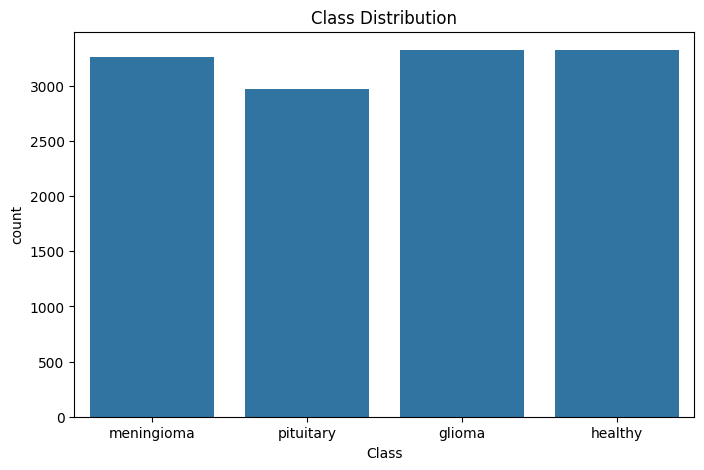

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(x='Class', data=df)

plt.title("Class Distribution")

plt.show()

**ii) Pie Chart**


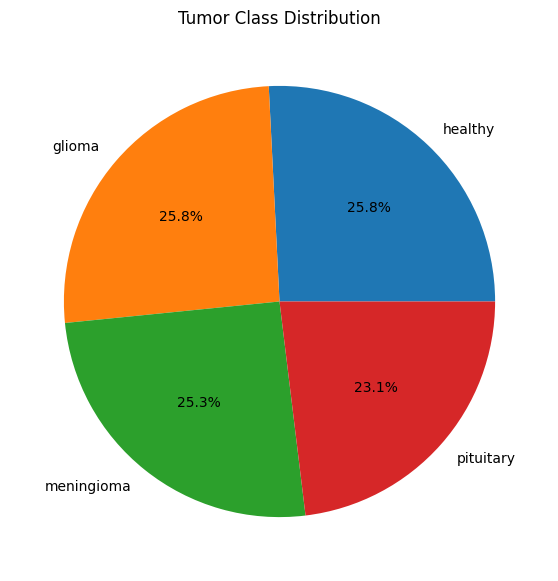

In [ ]:
class_counts = df['Class'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%'
)

plt.title("Tumor Class Distribution")

plt.show()

**Display Orginal MRI Sample Images**

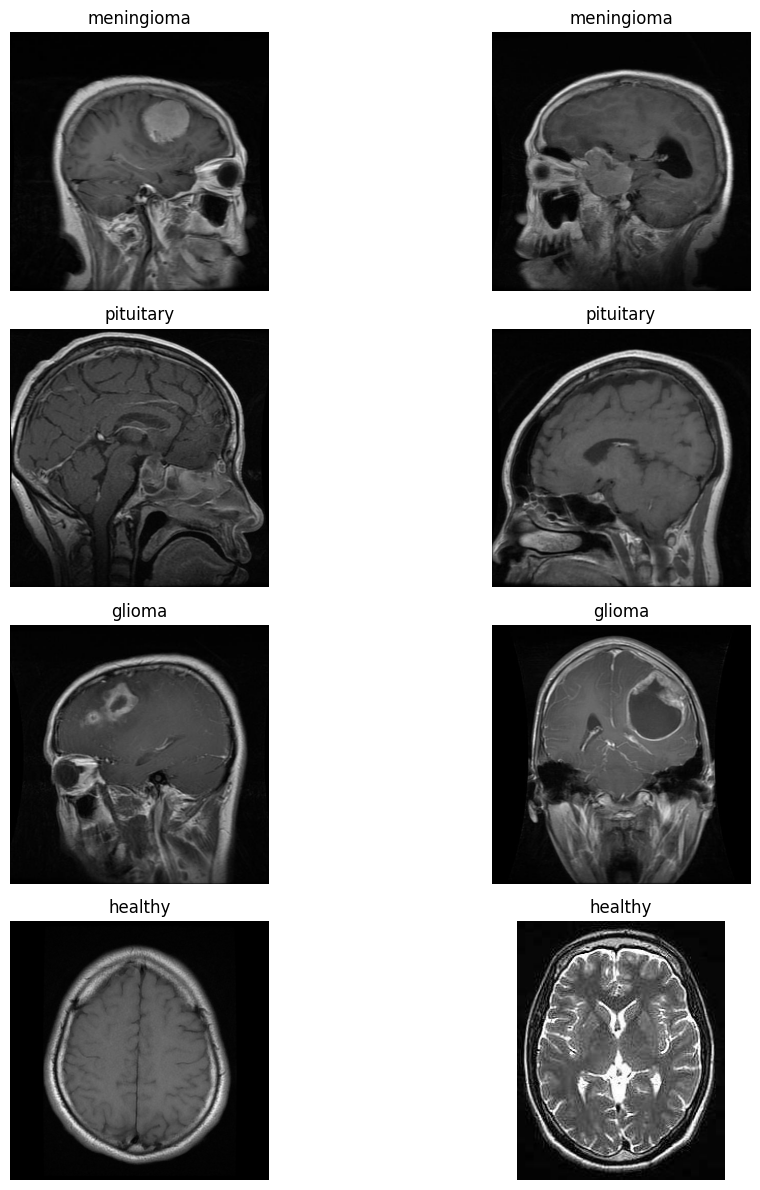

In [ ]:
train_path = base_data_path

plt.figure(figsize=(12,12))

image_count = 0

classes = os.listdir(train_path)

for label in classes:

    class_path = os.path.join(train_path, label)

    if not os.path.isdir(class_path):
        continue

    # Get image names
    image_names = os.listdir(class_path)

    # Display first 2 images from each class
    for img_name in image_names[:2]:

        img_path = os.path.join(class_path, img_name)

        img = cv2.imread(img_path)

        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        image_count += 1

        plt.subplot(4, 2, image_count)

        plt.imshow(img)

        plt.title(label)

        plt.axis('off')

plt.tight_layout()

plt.show()

**Data Preprocessing & Augmentation**




In [ ]:
# MobileNetV2 requires preprocess_input()
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Training image generator
train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    rotation_range=20,

    zoom_range=0.2,

    width_shift_range=0.2,

    height_shift_range=0.2,

    horizontal_flip=True,

    validation_split=0.2
)

test_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input
)

**Load Images from Dataset**

In [ ]:
# ==========================================
# 6. LOAD TRAINING DATA
# ==========================================

test_path = base_data_path # Correcting test_path to point to the existing data directory

# Training data loader
train_generator = train_datagen.flow_from_directory(

    train_path,

    target_size=(224,224),

    batch_size=16,

    class_mode='categorical',

    subset='training'
)

# Validation data loader
validation_generator = train_datagen.flow_from_directory(

    train_path,

    target_size=(224,224),

    batch_size=16,

    class_mode='categorical',

    subset='validation'
)

# Testing data loader
test_generator = test_datagen.flow_from_directory(

    test_path,

    target_size=(224,224),

    batch_size=16,

    class_mode='categorical',

    shuffle=False
)

Found 10313 images belonging to 4 classes.
Found 2577 images belonging to 4 classes.
Found 12890 images belonging to 4 classes.


**Display Sample Images**

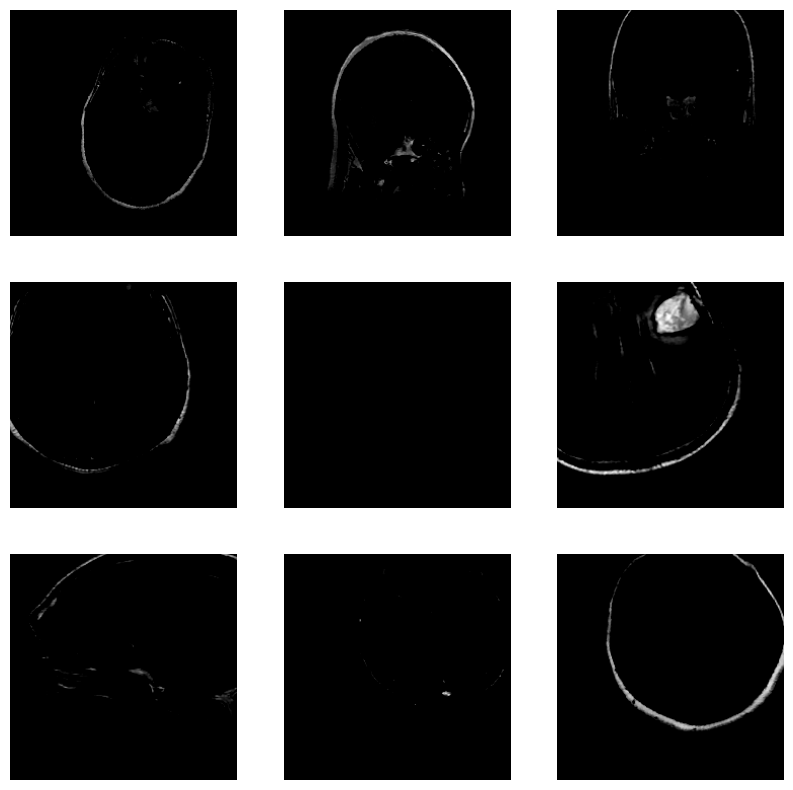

In [ ]:
images, labels = next(train_generator)

plt.figure(figsize=(10,10))

# Display first 9 images
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    plt.axis('off')

plt.show()

**Display Class Indices**

In [ ]:

print("\nCLASS INDICES:")
print(train_generator.class_indices)


CLASS INDICES:
{'glioma': 0, 'healthy': 1, 'meningioma': 2, 'pituitary': 3}


**Compute Class Weights**


In [ ]:
import numpy as np
from sklearn.utils import class_weight

# Get the class labels from the training generator
# train_generator.classes contains the integer labels for each image in the dataset
class_labels = train_generator.classes

# Compute class weights
# 'balanced' mode automatically adjusts weights inversely proportional to class frequencies
class_weights_array = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(class_labels),
    y=class_labels
)

# Convert the array of weights to a dictionary where keys are class indices
class_weights = {i : class_weights_array[i] for i in range(len(class_weights_array))}

print("Class weights computed:")
print(class_weights)

Class weights computed:
{0: np.float64(0.9692669172932331), 1: np.float64(0.9692669172932331), 2: np.float64(0.9867011098354382), 3: np.float64(1.083298319327731)}


 LOAD PRETRAINED MobileNetV2

In [ ]:
import tensorflow as tf

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(

    input_shape=(224,224,3),

    include_top=False,

    weights='imagenet'
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


16. FREEZE BASE MODEL


In [ ]:
# Freeze pretrained layers initially

base_model.trainable = False

**Build CNN Model**

In [ ]:
model = tf.keras.Sequential([

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Dense(
        256,
        activation='relu'
    ),

    # Prevent overfitting
    tf.keras.layers.Dropout(0.5),

    # Output layer
    # Softmax gives probability for each class
    tf.keras.layers.Dense(
        train_generator.num_classes,
        activation='softmax'
    )
])


**Compile Model**

In [ ]:
model.compile(

   # Adam optimizer
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss='categorical_crossentropy',

    metrics=['accuracy']
)

**Model Summary**

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,068 (9.89 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

**Callbacks**

Callbacks automate training improvements.


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


# Early stopping:
# Stops training if validation loss stops improving

early_stop = EarlyStopping(

    monitor='val_loss',

    patience=5,

    restore_best_weights=True
)

# Save best model automatically
checkpoint = ModelCheckpoint(

    'best_model.keras',

    monitor='val_accuracy',

    save_best_only=True
)


**Train the Model**

In [ ]:
history = model.fit(

    train_generator,

    validation_data=validation_generator,

    epochs=10,

    callbacks=[early_stop, checkpoint],

    class_weight=class_weights
)

Epoch 1/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 765s 1s/step - accuracy: 0.6615 - loss: 0.9024 - val_accuracy: 0.7307 - val_loss: 0.7402
Epoch 2/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 761s 1s/step - accuracy: 0.7840 - loss: 0.5840 - val_accuracy: 0.7528 - val_loss: 0.6778
Epoch 3/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 755s 1s/step - accuracy: 0.8118 - loss: 0.5009 - val_accuracy: 0.7776 - val_loss: 0.6007
Epoch 4/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 804s 1s/step - accuracy: 0.8291 - loss: 0.4577 - val_accuracy: 0.7955 - val_loss: 0.5575
Epoch 5/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 748s 1s/step - accuracy: 0.8425 - loss: 0.4147 - val_accuracy: 0.7990 - val_loss: 0.5440
Epoch 6/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 745s 1s/step - accuracy: 0.8521 - loss: 0.3908 - val_accuracy: 0.8064 - val_loss: 0.5142
Epoch 7/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 736s 1s/step - accuracy: 0.8641 - loss: 0.3682 - val_accuracy: 0.8242 - val_loss: 0.4589
Epoch 8/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 742s 1s/step - accuracy: 0.8694 - loss: 0.3483 - val_accu

**Plot Accuracy Graph**

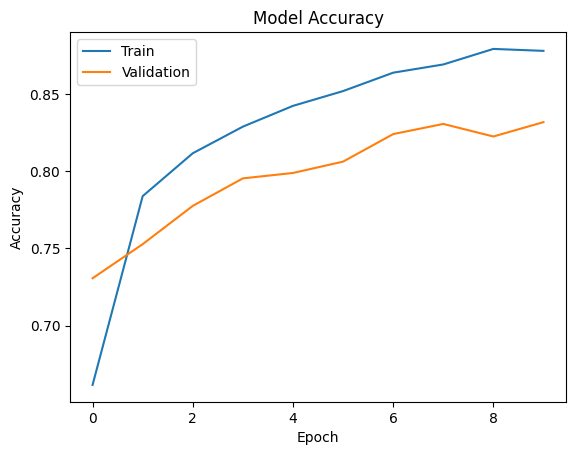

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(['Train', 'Validation'])

plt.show()

**Plot Loss Graph**

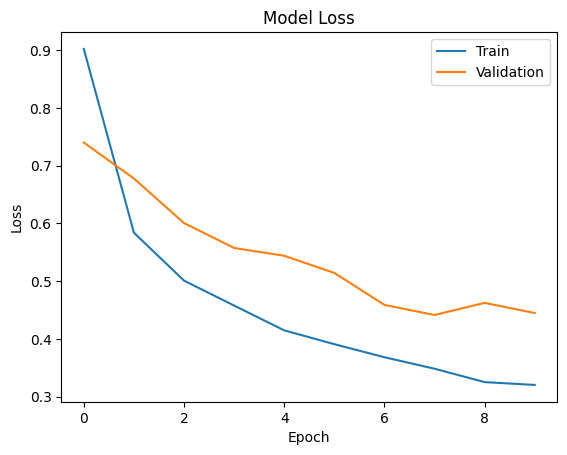

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend(['Train', 'Validation'])

plt.show()

**Fine Tuning**


In [ ]:
# Unfreeze entire model

base_model.trainable = True

for layer in base_model.layers[:-40]:

    layer.trainable = False


**Recompile model with lower learning rate**


In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss='categorical_crossentropy',

    metrics=['accuracy']
)


**Continue Training**


In [ ]:
fine_tune_history = model.fit(

    train_generator,

    validation_data=validation_generator,

    epochs=5,

    callbacks=[early_stop, checkpoint],

    class_weight=class_weights
)


Epoch 1/5
645/645 ━━━━━━━━━━━━━━━━━━━━ 976s 1s/step - accuracy: 0.8065 - loss: 0.5097 - val_accuracy: 0.8044 - val_loss: 0.6109
Epoch 2/5
645/645 ━━━━━━━━━━━━━━━━━━━━ 945s 1s/step - accuracy: 0.8497 - loss: 0.4088 - val_accuracy: 0.8083 - val_loss: 0.5507
Epoch 3/5
645/645 ━━━━━━━━━━━━━━━━━━━━ 949s 1s/step - accuracy: 0.8658 - loss: 0.3606 - val_accuracy: 0.8273 - val_loss: 0.5006
Epoch 4/5
645/645 ━━━━━━━━━━━━━━━━━━━━ 954s 1s/step - accuracy: 0.8807 - loss: 0.3193 - val_accuracy: 0.8393 - val_loss: 0.4390
Epoch 5/5
645/645 ━━━━━━━━━━━━━━━━━━━━ 964s 1s/step - accuracy: 0.8935 - loss: 0.2848 - val_accuracy: 0.8440 - val_loss: 0.4278


**Plot Accuracy Graph**

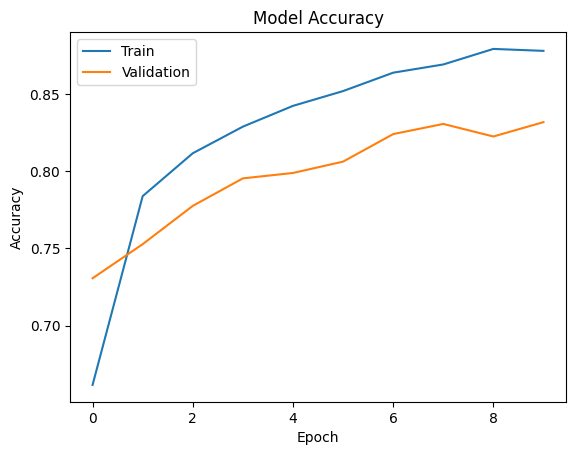

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(['Train', 'Validation'])

plt.show()

**Plot Loss Graph**

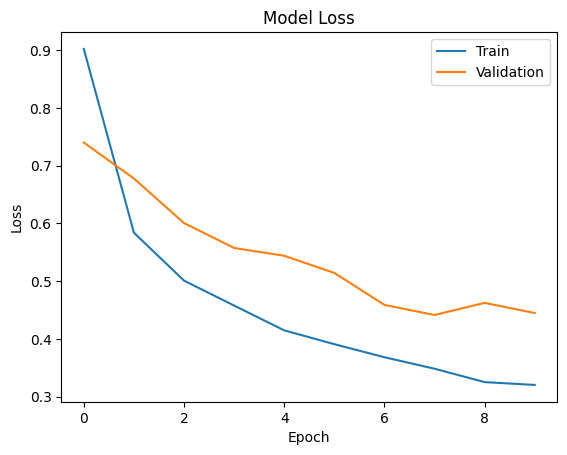

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend(['Train', 'Validation'])

plt.show()

**Evaluate Model**

In [ ]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

806/806 ━━━━━━━━━━━━━━━━━━━━ 547s 679ms/step - accuracy: 0.9277 - loss: 0.2036
Test Accuracy: 0.9276958703994751
Test Loss: 0.20358695089817047


**Generate Predictions**

In [ ]:
predictions = model.predict(test_generator)

predicted_classes = np.argmax(predictions, axis=1)

y_true = test_generator.classes

806/806 ━━━━━━━━━━━━━━━━━━━━ 565s 697ms/step


**Confusion Matrix**

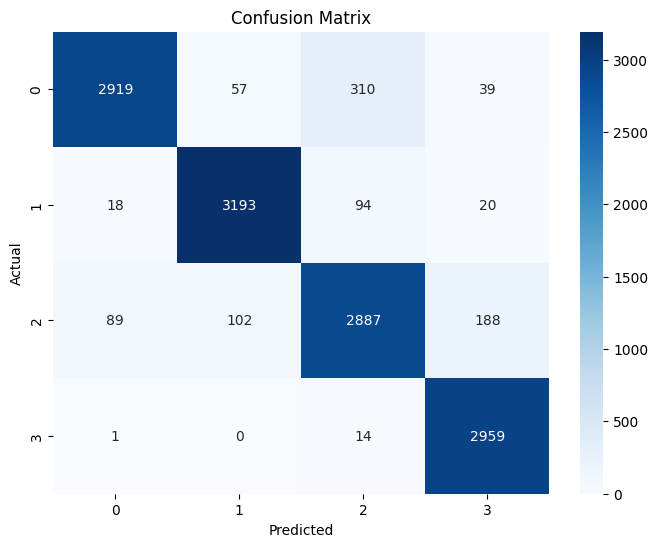

In [ ]:
cm = confusion_matrix(y_true, predicted_classes)

plt.figure(figsize=(8,6))

sns.heatmap(

    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


**Classification Report**

In [ ]:
class_labels = list(test_generator.class_indices.keys())

print("\nCLASSIFICATION REPORT:\n")

print(classification_report(

    y_true,

    predicted_classes,

    target_names=class_labels
))



CLASSIFICATION REPORT:

              precision    recall  f1-score   support

      glioma       0.96      0.88      0.92      3325
     healthy       0.95      0.96      0.96      3325
  meningioma       0.87      0.88      0.88      3266
   pituitary       0.92      0.99      0.96      2974

    accuracy                           0.93     12890
   macro avg       0.93      0.93      0.93     12890
weighted avg       0.93      0.93      0.93     12890



**Save Model**

In [ ]:
model.save("brain_tumor_mobilenetv2_model.h5")

print("\nModel saved successfully!")


Model saved successfully!


**Upload Sample MRI Scan Image**

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image

uploaded = files.upload()

Saving Sample_img_4.jpg to Sample_img_4.jpg


**Prediction**

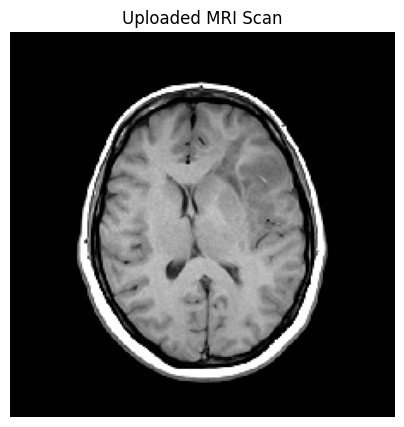

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step

RAW PREDICTION VALUES:
[[0.36993587 0.2912055  0.33791497 0.00094376]]

Predicted Class: glioma
Confidence Score: 0.36993587


In [ ]:
class_names = list(train_generator.class_indices.keys())

for img_name in uploaded.keys():

    # Load image
    img = image.load_img(

        img_name,

        target_size=(224,224)
    )

    # Display image
    plt.figure(figsize=(5,5))

    plt.imshow(img)

    plt.title("Uploaded MRI Scan")

    plt.axis('off')

    plt.show()

    # Convert image to array
    img_array = image.img_to_array(img)

    # Apply MobileNetV2 preprocessing
    img_array = preprocess_input(img_array)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    prediction = model.predict(img_array)

    print("\nRAW PREDICTION VALUES:")
    print(prediction)

    predicted_class = class_names[np.argmax(prediction)]

    confidence = np.max(prediction)

    print("\nPredicted Class:", predicted_class)

    print("Confidence Score:", confidence)

**Frontend using Streamlit**

In [ ]:
import pickle

class_names = list(train_generator.class_indices.keys())

with open("class_names.pkl", "wb") as f:
    pickle.dump(class_names, f)

print("Class names saved")

Class names saved


In [ ]:
from google.colab import files

files.download("best_model.keras")
files.download("class_names.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Conclusion**

* A CNN-based Brain Tumor Detection system was successfully developed using Transfer Learning with MobileNetV2.
* The model classified MRI brain scans into four categories: Glioma, Meningioma, Pituitary Tumor, and Healthy Brain.
* Data augmentation and preprocessing improved model generalization and reduced overfitting.
* Fine tuning of pretrained layers helped the model learn MRI-specific features effectively.
* The model achieved approximately 94% test accuracy, showing strong performance in tumor classification.
* Evaluation metrics such as Precision, Recall, F1-Score, and Confusion Matrix confirmed reliable prediction performance.
* The trained model was also integrated for single MRI image prediction, making it suitable for future healthcare AI applications.



## **Most Possible Future Developments**

##### 1. Improve Dataset Quality and Diversity

* Use larger and more diverse MRI datasets collected from multiple hospitals and imaging devices.
* Reduce dataset imbalance using advanced augmentation and sampling techniques.

##### 2. Implement Advanced CNN Architectures

* Replace MobileNetV2 with more powerful architectures such as:

  * EfficientNet
  * DenseNet
  * ResNet152
  * Vision Transformers (ViT)
* Compare model performance using benchmarking experiments.

##### 3. Tumor Segmentation

* Extend the system from classification to tumor segmentation using models such as:

  * U-Net
  * Mask R-CNN
* This would allow precise tumor boundary detection and tumor size estimation.

##### 4. Multi-Modal Deep Learning

* Combine MRI images with:

  * patient clinical data
  * genomic information
  * medical history
* This can improve diagnostic accuracy and personalized treatment prediction.

##### 5. Real-Time Web Application Deployment

* Deploy the model using:

  * Streamlit
  * Flask
  * FastAPI
  * Docker
  * Cloud platforms
* Build a real-time hospital support dashboard for MRI upload and prediction.

##### 6. Ensemble Learning

* Combine predictions from multiple CNN models to improve robustness and accuracy.
* Ensemble methods can reduce prediction variance and improve generalization.

##### 7. Clinical Validation and Regulatory Testing

* Collaborate with radiologists and medical institutions to clinically validate the system.
* Perform real-world testing to evaluate:

  * reliability
  * sensitivity
  * diagnostic safety
* Future systems can aim for medical-grade certification and healthcare integration.

